(paramfit_gof_ntbk)=

# Goodness of fit

Once the fundamental parameters of an observed cluster have been estimated, e.g. with any of the [Parameters fit](../paramfit) tutorials, we want to know whether the synthetic cluster generated with those parameters is actually a good representation of the observed cluster.

The likelihood (or distance) used during the fit is useful to compare synthetic clusters for the *same* observed cluster, but its value can not be compared across clusters: even a perfect model gives a value different from the optimal one, by an amount that depends on the number of stars (and, for binned likelihoods, on the number of cells). To assess the fit we use the [cmd_overlap()](asteca.Synthetic.cmd_overlap) method instead, whose value can be compared across clusters with any number of stars (see {ref}`Goodness of fit <cmd_overlap>`).

We start by loading the same observed cluster and isochrones used in the parameters fit tutorials, and calibrating a [Synthetic](asteca.Synthetic) object with the observed cluster:

In [1]:
import asteca
import pandas as pd

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=0
)

# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=0)

# Load the observed cluster
obs_df = pd.read_csv("../../_static/cluster.csv")
my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"],
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=0
)

# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)

The fitted parameters are stored in a `fit_params` dictionary. Here we use the medians obtained in the [Parameters fit with asteca.Sampler](paramfit_sampler_ntbk) tutorial; the parameters not included keep the default values of the `synthcl` object:

In [2]:
# Medians of the fitted parameters
fit_params = {
    "met": 0.014,
    "loga": 7.934,
    "dm": 8.200,
    "Av": 0.505,
}

We can generate a CMD comparing our observed cluster with the synthetic cluster generated with the medians, using the medians of the parameter distributions stored in the `fit_params` dictionary:

In [3]:
# Generate the synthetic cluster using these parameters
synth_arr = synthcl.generate(fit_params)

## CMD overlap

The [cmd_overlap()](asteca.Synthetic.cmd_overlap) method compares the synthetic cluster with the observed cluster used to calibrate the `synthcl` object. It returns the value `D`, which is `0` for a synthetic cluster drawn from the same distribution as the observed one and `1` when the two do not overlap in the CMD, and `D_std`, the approximate standard deviation of `D` for a correct model (it decreases with the number of stars). In tests with simulated clusters, `D<=0.25` was found to be a reasonable general threshold for a good fit:

In [4]:
# CMD overlap between the observed cluster and this synthetic cluster
D, D_std = synthcl.cmd_overlap(synth_arr)
print("CMD overlap (D): {:.3f} +/- {:.3f}".format(D, D_std))

CMD overlap (D): 0.043 +/- 0.003


Finally, we can generate a side-by-side CMD plot showing also the theoretical isochrone associated to this synthetic cluster:

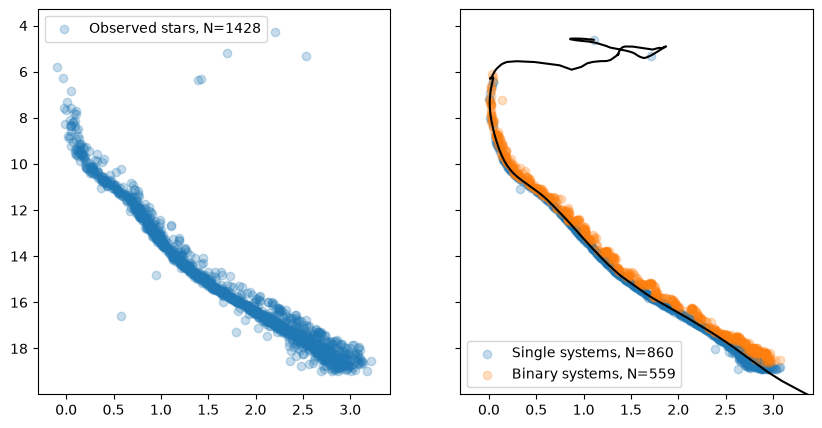

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def cmd_plot(color, mag, label, ax=None):
    """Function to generate a CMD plot"""
    if ax is None:
        ax = plt.subplot(111)
    label = label + f", N={len(mag)}"
    ax.scatter(color, mag, alpha=0.25, label=label)
    ax.legend()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
# Observed cluster
cmd_plot(my_cluster.color, my_cluster.mag, "Observed stars", ax1)

# Synthetic cluster
# Boolean mask identifying the binary systems
binary_msk = ~np.isnan(synth_arr[-1])
# Extract magnitude and color
mag, color = synth_arr[0], synth_arr[1]
# Plot single systems
cmd_plot(color[~binary_msk], mag[~binary_msk], "Single systems", ax2)
# Plot binary systems
cmd_plot(color[binary_msk], mag[binary_msk], "Binary systems", ax2)

# Get isochrone associated to the synthetic cluster
isoch_arr = synthcl.get_isochrone(fit_params)
# Plot the isochrone
ax2.plot(isoch_arr[1], isoch_arr[0], c="k")

# Same ranges in both plots, defined by the observed cluster (inverted y axis)
ax1.set_xlim(np.nanmin(my_cluster.color) - 0.2, np.nanmax(my_cluster.color) + 0.2)
ax1.set_ylim(np.nanmax(my_cluster.mag) + 1, np.nanmin(my_cluster.mag) - 1);